In [1]:
import at
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pickle

from copy import deepcopy

In [16]:
matlab = scipy.io.loadmat('/gpfs/offline1/staff/common/alfpet/git/Max4U/CandidateLattices/m4U_251123_n01_02_01_01/m4U_251123_n01_02_01_01.mat', simplify_cells=True)

ring0 = at.load_var(deepcopy(matlab['m4U_251123_n01_02_01_01']['ACHROMAT']))
chrom_fams = matlab['m4U_251123_n01_02_01_01']['cLoptions']['chrom_fams']
ringtune_fams = matlab['m4U_251123_n01_02_01_01']['cLoptions']['ringtune_fams']

/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/lattice/elements/element_object.py:294: AtWarning: Element Q1_n1: Duplicate element data, both positional argument 'poly_b' and 'K' in kwargs passed.
  element = cls(*(arg for arg in elem_args if arg is not None), **elem_dict)
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/lattice/elements/element_object.py:294: AtWarning: Element Q2_n1: Duplicate element data, both positional argument 'poly_b' and 'K' in kwargs passed.
  element = cls(*(arg for arg in elem_args if arg is not None), **elem_dict)
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/lattice/elements/element_object.py:294: AtWarning: Element Q2_n1: Duplicate element data, both positional argument 'poly_b' and 'K' in kwargs passed.
  element = cls(*(arg for arg in elem_args if arg is not None), **elem_dict)
/gpfs/offline1/staff/common/alfpet/gi

In [17]:
N = len(ring0)
s_pos = ring0.get_s_pos()

In [18]:
UC_index = ring0.uint32_refpts('UCborder')

print("Matching section:")
print([e.FamName for e in ring0[:UC_index[0] + 1]])

print("Unit cell:")
print([e.FamName for e in ring0[UC_index[0] : UC_index[1]+1]])

Matching section:
['str0500', 'str0500', 'str0500', 'str0500', 'str0321', 'GS', 'bpm_d', 'BPM', 'bpm_d', 'str0010', 'corrh_ac', 'corrv_ac', 'str0048', 'corr_d', 'corrv', 'corr_d', 'corr_d', 'corrh', 'corr_d', 'str0021', 'O1_n1', 'O1_n1', 'str0025', 'Q1_n1', 'str0025', 'O2_n1', 'O2_n1', 'str0100', 'Q2_n1', 'strx006', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'D1_n1', 'O3_n1', 'corrv', 'O3_n1', 'strx093', 'corr_d', 'corr_d', 'corr_d', 'corrh', 'corr_d', 'bpm_d', 'BPM', 'bpm_d', 'str0020', 'S1_n1', 'LSborder', 'S1_n1', 'GE', 'str2', 'GS', 'R1_n1', 'str1', 'S2_n1', 'UCborder']
Unit cell:
['UCborder', 'S2_n1', 'strx013', 'bpm_d', 'BPM', 'bpm_d', 'strx013', 'R2_n1', 'str0100', 'corr_d', 'corrv', 'corr_d', 'corr_d', 'corrh', 'corr_d', 'strx203', 'S3_n1', 'S3_n1', 'str0010', 'str3', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'D2_n1', 'str3', 'str0

## Adjust geometry

In [5]:
ring = deepcopy(ring0) # Create new ring
description = "Based on m4U_251123_n01_02_01_01, with R1 turned into a pure quadrupole (D1 increased)"

theta0 = ring0.get_elements('R1_n1')[0].BendingAngle 
d_theta = theta0

R1_n1 = ring.get_elements('R1_n1')
D_comp = ring.get_elements('D1_n1') # Which dipoles to compensate with

# Decrease bending angle of R1
for element in ring.get_elements('R1_n1'):
    element.BendingAngle -= d_theta 

# Compensate by increasing bending angle of D_comp
for element in D_comp:
    element.BendingAngle += len(R1_n1) / len(D_comp) * d_theta 

In [6]:
adjusted_drifts = ['strx093']

# Variables
variables = at.VariableList(at.RefptsVariable(name, "Length", bounds=(0.0, np.inf), delta=1e-3, name=name, ring=ring) for name in adjusted_drifts)


# Observables
def circumference(ring, **__):
    return ring.get_s_pos(len(ring))[0]

obs = at.ObservableList()
obs.append(at.GeometryObservable(refpts=at.End, param='x', target=ring0.get_geometry(at.End)[0].x))
obs.append(at.GeometryObservable(refpts=at.End, param='y', target=ring0.get_geometry(at.End)[0].y))
# obs.append(at.RingObservable(circumference, target=circumference(ring0)))

ring.match(
    variables,
    obs,
    copy=False,
    verbose=2,
)


2 constraints, 1 variables, using method trf

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         1.1901e-07                                    8.96e-05    
       1              2         8.3484e-13      1.19e-07       2.45e-04       2.37e-07    
       2              3         4.1398e-23      8.35e-13       6.52e-07       1.67e-12    
`gtol` termination condition is satisfied.
Function evaluations 3, initial cost 1.1901e-07, final cost 4.1398e-23, first-order optimality 1.67e-12.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
geometry[x]
    End                   25.9011           25.9006           25.9006           25.9006       2.91821e-08 
geometry[y]
    End                  -4.10232          -4.10224          -4.10224          -4.10224      -4.62197e-09 

Variables:

        Name      Initial          Final        Variation

     strx

## Optics matching

In [7]:
# Correct beta beating and dispersion
elemdata_UC = at.linopt4(ring[UC_index[0]:UC_index[1]+1], at.All)[0] # Optics functions required for matching

# For scaling D1 strengths
D1_refpts = ring0.uint32_refpts('D1_n1')
D1_K0 = np.array([ring0[i].K for i in D1_refpts])

def set_D1_scale(value):
    for i, K0 in zip(D1_refpts, D1_K0):
        ring[i].K = value* K0

def get_D1_scale(**kwargs):
    return ring[D1_refpts[0]].K / D1_K0[0]

vars = at.VariableList([
    at.CustomVariable(set_D1_scale, get_D1_scale, name='D1 scale', delta=1e-3),
    at.RefptsVariable('R1_n1', attrname='K', name='R1', delta=1e-5),
    at.RefptsVariable('Q1_n1', attrname='K', name='Q1', delta=1e-5),
    at.RefptsVariable('Q2_n1', attrname='K', name='Q2', delta=1e-5),
])

obs = at.ObservableList([
    at.LocalOpticsObservable(UC_index[0], 'beta', plane='x', target=elemdata_UC.beta[0]),
    at.LocalOpticsObservable(UC_index[0], 'beta', plane='y', target=elemdata_UC.beta[1]),
    at.LocalOpticsObservable(UC_index[0], 'alpha', plane='x', target=0),
    at.LocalOpticsObservable(UC_index[0], 'alpha', plane='y', target=0),
    at.LocalOpticsObservable(0, 'dispersion', plane=0, target=0),
    at.LocalOpticsObservable(0, 'dispersion', plane=0, target=0),
])

ring.match(vars, obs, verbose=2)


6 constraints, 4 variables, using method lm

`xtol` termination condition is satisfied.
Function evaluations 95, initial cost 6.1188e-04, final cost 4.3870e-22, first-order optimality 9.24e-12.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
beta[x]
    UCborder              6.24577           6.27119           6.27118           6.27118       1.07958e-07 
beta[y]
    UCborder              2.48577           2.48094           2.48094           2.48094       1.78138e-08 
alpha[x]
    UCborder          4.24092e-05      -2.03619e-10               0.0               0.0      -2.03619e-10 
alpha[y]
    UCborder         -1.11643e-05      -2.38062e-11               0.0               0.0      -2.38062e-11 
dispersion[x]
    str0500            -0.0166497       4.53417e-15               0.0               0.0       4.53417e-15 
dispersion[x]
    str0500            -0.0166497       4.53417e-15               0.0               0.

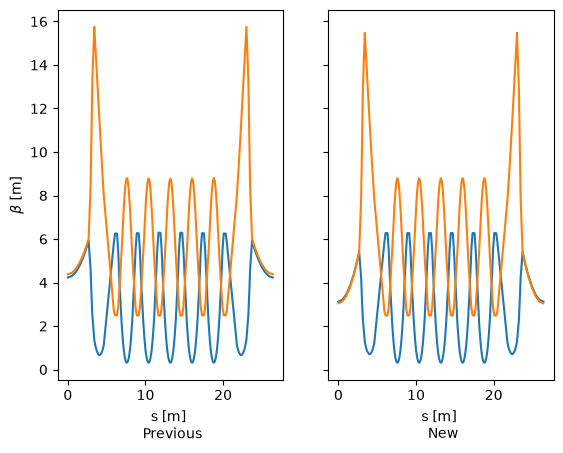

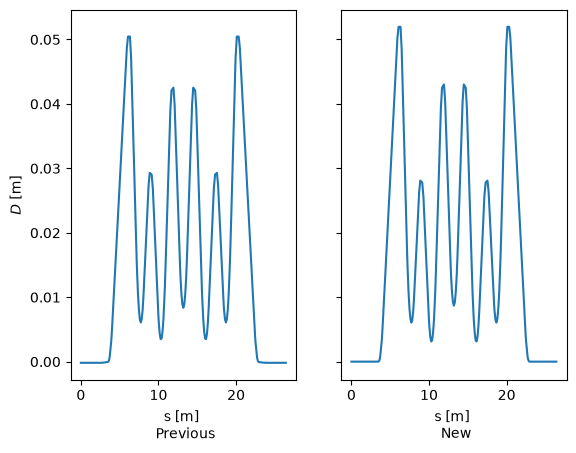

In [8]:
elemdata0 = ring0.linopt4(at.All)[2]
elemdata = ring.linopt4(at.All)[2]

fig, axs = plt.subplots(1, 2, sharey=True)
axs[0].plot(elemdata0.s_pos, elemdata0.beta)
axs[1].plot(elemdata.s_pos, elemdata.beta)
axs[0].set_xlabel('s [m] \n Previous')
axs[1].set_xlabel('s [m] \n New')
axs[0].set_ylabel('$\\beta$ [m]')
plt.show()

fig, axs = plt.subplots(1, 2, sharey=True)
axs[0].plot(elemdata0.s_pos, elemdata0.dispersion[:, 0])
axs[1].plot(elemdata.s_pos, elemdata.dispersion[:, 0])
axs[0].set_xlabel('s [m] \n Previous')
axs[1].set_xlabel('s [m] \n New')
axs[0].set_ylabel('$D$ [m]')
plt.show()

In [15]:
print(ring0.get_tune(get_integer=True))

[58.32018081 17.16762258]


Tunes: [58.32 17.17] -> [58.87 18.35]
Chromaticity: [2.07 1.93] -> [ 2.88 -0.5 ]


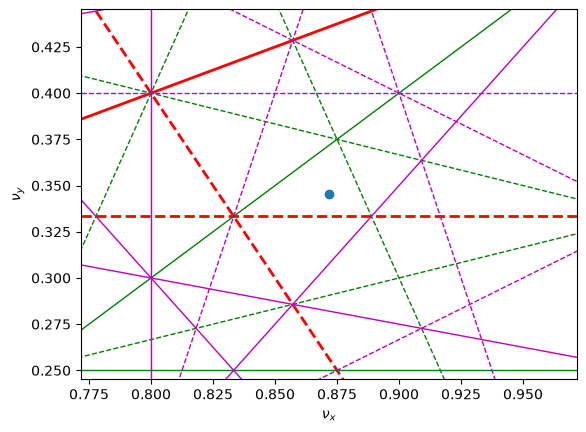

In [9]:
print(f'Tunes: {ring0.get_tune(get_integer=True).round(2)} -> {ring.get_tune(get_integer=True).round(2)}')
print(f'Chromaticity: {ring0.get_chrom().round(2)} -> {ring.get_chrom().round(2)}')

tunes = ring.get_tune()
at.plot.resonances.plot_tune_diagram(orders=[1, 2, 3, 4, 5], show=False)
plt.scatter(*tunes)
plt.xlim(tunes[0]-0.1, tunes[0]+0.1)
plt.ylim(tunes[1]-0.1, tunes[1]+0.1)
plt.show()

In [10]:
# Correct chromaticity
xi0 = ring0.get_chrom()
at.fit_chrom(ring, chrom_fams[0], chrom_fams[1], xi0) 


Fitting Chromaticity...
Initial value [ 2.88462334 -0.49930923]
iter# 0 Res. 8.285456924184717e-07
iter# 1 Res. 9.751863449086141e-14
Final value [2.0661831  1.93140686] 



## Renaming

In [11]:
old_names = [e.FamName for e in ring0]

for element, old_name in zip(ring, old_names):
    # Change of types
    if 'R1' in old_name:
        element.FamName = old_name.replace('R1', 'Q3')
    if 'R2' in old_name:
        element.FamName = old_name.replace('R2', 'R1')
    if 'strx093' in old_name:
        new_name = 'strx' + f'{element.Length:.3f}'.removeprefix('0.')
        element.FamName = new_name

    # Change lattice identifier
    element.FamName = element.FamName.replace('_n1', '_v1')

np.unique([e.FamName for e in ring])

array(['BPM', 'D1_v1', 'D2_v1', 'GE', 'GS', 'LSborder', 'O1_v1', 'O2_v1',
       'O3_v1', 'Q1_v1', 'Q2_v1', 'Q3_v1', 'R1_v1', 'S1_v1', 'S2_v1',
       'S3_v1', 'S4_v1', 'UCborder', 'bpm_d', 'corr_d', 'corrh',
       'corrh_ac', 'corrv', 'corrv_ac', 'str0010', 'str0020', 'str0021',
       'str0025', 'str0048', 'str0075', 'str0100', 'str0321', 'str0500',
       'str1', 'str2', 'str3', 'strx006', 'strx013', 'strx092', 'strx203',
       'strx403'], dtype='<U8')

## Save lattice

In [ ]:
lattice_name = 'm4U_260915_v01_01_01_01'

with open(f'candidates/{lattice_name}.pkl', 'wb') as file:
    pickle.dump(ring, file)

at.save_mat(ring, f'candidates/{lattice_name}/achro.mat')